In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import cross_val_predict
dataset = pd.read_csv('Car Details v3.csv')
print(dataset.info())
print(dataset.shape)
print(dataset.isna().sum())
print(f'Дубликаты: {dataset.duplicated().sum()}')
dataset.head()


<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB
None
(8128, 13)
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


# Предсказание цены подержанного автомобиля (CarDekho)

## Цель
Оценить рыночную цену подержанного автомобиля по его характеристикам, чтобы продавец мог выставить адекватную цену, а покупатель оценить предложение.

## Данные
Car details v3 (CarDekho): 8128 объявлений, 13 столбцов. После очистки: [6698] строк, 11 признаков + цена.

## Что предсказываем
Целевая переменная `selling_price` (цена продажи в рупиях). Тип задачи: **регрессия**.

## Момент предсказания
Цена оценивается при выставлении объявления или перед покупкой. Доступны год выпуска, пробег, тип топлива, тип продавца, коробка передач, число владельцев, расход, объём двигателя, мощность, число мест и марка. Признаков, которые становятся известны только после продажи (утечка), нет.

## Метрика
Основная: **MAE в рупиях** (понятна пользователю: на сколько в среднем ошибается модель). Дополнительно: медиана относительной ошибки |ошибка| / цена, так как MAE в рупиях сильнее «взвешивает» дорогие машины.

## Валидация
- Дубликаты удалены до разбиения (1202 полных повтора + [19] повторов по признакам и цене), чтобы одна и та же запись не попала и в train, и в проверку.
- Разбиение train / test = 80 / 20, `random_state=42`. Тест используется один раз, в конце.
- Выбор и сравнение моделей: 5-кратная кросс-валидация на train.
- Модель обучается на `log1p(цена)`, а метрика считается в рупиях (предсказания возвращаются через `expm1`).

## Baseline
`DummyRegressor` с медианой train: MAE ≈ [281] ± [6] тыс. ₽ (≈ [66]% от медианной цены 425 тыс. ₽). Предсказание медианой лучше предсказания средним (≈ [295] тыс. ₽).

## Критерий успеха
На CV: MAE ≤ 127 тыс. ₽ (минимум, снижение ошибки относительно baseline не менее 55%, ≈ 30% от медианной цены) и желательно ≤ 106 тыс. ₽ (снижение не менее 62%, ≈ 25% от медианной цены). Улучшение должно быть заметно больше std кросс-валидации. После подбора модели результат подтверждается один раз на test.

## Риски и ограничения
- Дубликаты в данных (удалены).
- Пропуски: у ≈ 3% объявлений нет технических характеристик (удалены, поэтому для таких машин модель не работает).
- Сильно скошенная цена (обучение на log1p).
- Текстовые столбцы с единицами (`mileage`: kmpl и km/kg, `engine`, `max_power`): приведены к числам; `torque` исключён (разные единицы, грязный формат).
- Выбросы: нереальный пробег (удаляется только из train); дорогие машины раздувают MAE в рупиях.
- Редкие категории (CNG, LPG, «Test Drive Car», редкие марки): `handle_unknown='ignore'`.
- В данных нет состояния машины, комплектации, региона и торга, поэтому полностью точное предсказание невозможно.

В нашем датасете находится 8128 строк и 12 столбцов из них 1202 дубликаты, присутствуют пропуски в столбцах torque и seats, max_power, engine,mileage, в названиях включены марки автомобиля их нужно будет определить в отдельный столбец и добавить как еще одну категорию на основе которой модель может делать предсказания

In [2]:
dataset[dataset['mileage'].isna()].isna().sum()


name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           221
seats            221
dtype: int64

тк пропуски совпадают это говорит о том что эти дубликаты это полностью машины без характеристик их около 3% от общего числа значит просто удалим их

In [3]:
dataset = dataset.drop_duplicates().dropna().reset_index(drop= True)

dataset = dataset.drop(columns = 'torque')
print(dataset.shape)

(6717, 12)


после удаления дубликатов и пустых строк строк стало 6717

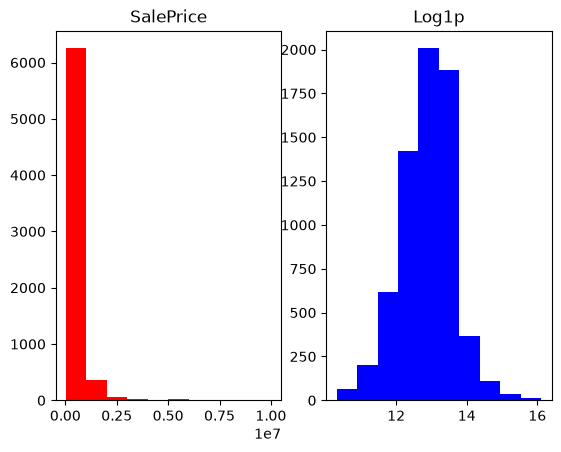

In [4]:
fig, ax = plt.subplots(1,2)

ax[0].hist(dataset.selling_price,color = 'red', label = 'SalePrice')

ax[1].hist(np.log1p(dataset.selling_price),color = 'Blue', label = 'Log1p')
ax[0].set_title('SalePrice')
ax[1].set_title('Log1p')
plt.show()

Можем заметить что гистограмма по Saleprice крайне не симметрична, а по log1p уже более симметричная и лучше обучать на таких данных, но в конце нужно будет вернуть числа обратно в рупии через expm1

In [5]:
print(dataset.fuel.value_counts())
print()
print(dataset.seller_type.value_counts())
print()
print(dataset.transmission.value_counts())
print()
print(dataset.owner.value_counts())
print()
dataset = dataset.copy()


fuel
Diesel    3658
Petrol    2973
CNG         51
LPG         35
Name: count, dtype: int64

seller_type
Individual          6024
Dealer               666
Trustmark Dealer      27
Name: count, dtype: int64

transmission
Manual       6142
Automatic     575
Name: count, dtype: int64

owner
First Owner             4176
Second Owner            1888
Third Owner              493
Fourth & Above Owner     155
Test Drive Car             5
Name: count, dtype: int64



In [6]:
for col in ['mileage', 'engine', 'max_power']:
    print(dataset[col].str.split().str[1].value_counts())
    print()
print(pd.crosstab(dataset['mileage'].str.split().str[1], dataset['fuel']))

dataset.mileage = dataset.mileage.str.split().str[0].astype(float)
print(dataset['mileage'])
print()
dataset.engine = dataset.engine.str.split().str[0].astype(float)
print(dataset['engine'])
print()
mp = pd.to_numeric(dataset['max_power'].str.split().str[0], errors='coerce')
print(mp.isna().sum())
print()
dataset['max_power'] = mp

mileage
kmpl     6631
km/kg      86
Name: count, dtype: int64

engine
CC    6717
Name: count, dtype: int64

max_power
bhp    6717
Name: count, dtype: int64

fuel     CNG  Diesel  LPG  Petrol
mileage                          
km/kg     51       0   35       0
kmpl       0    3658    0    2973
0       23.40
1       21.14
2       17.70
3       23.00
4       16.10
        ...  
6712    18.90
6713    22.54
6714    18.50
6715    16.80
6716    19.30
Name: mileage, Length: 6717, dtype: float64

0       1248.0
1       1498.0
2       1497.0
3       1396.0
4       1298.0
         ...  
6712     998.0
6713    1396.0
6714    1197.0
6715    1493.0
6716    1248.0
Name: engine, Length: 6717, dtype: float64

0



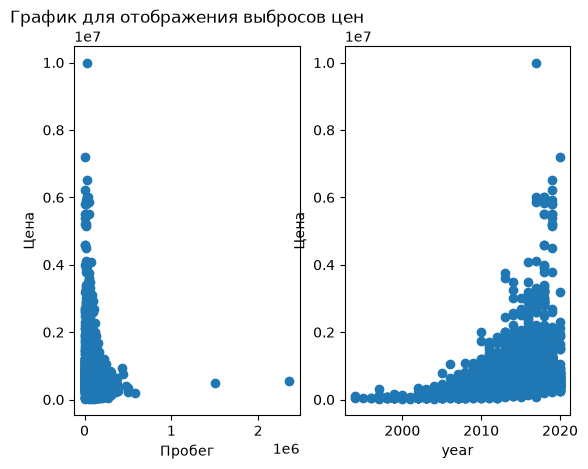

In [7]:
fig, ax = plt.subplots(1,2)

ax[0].scatter(dataset['km_driven'], dataset['selling_price'],label = 'selling price')

ax[0].set_title('График для отображения выбросов цен')
ax[0].set_ylabel('Цена')
ax[0].set_xlabel('Пробег')
ax[1].set_ylabel('Цена')
ax[1].set_xlabel('year')
ax[1].scatter(dataset['year'], dataset['selling_price'],label = 'selling price')
plt.show()




выбросы есть по пробегу их нужно убрать из тренировочной выборки так как они будут сбивать модель

In [8]:

dataset['brand'] = dataset['name'].str.split().str[0]
dataset['brand'] = dataset['brand'].replace({
    'Land': 'Land Rover',
    'Force': 'Force Motors',
    'Ashok': 'Ashok Leyland',
})
print(dataset['brand'].value_counts())



brand
Maruti           2089
Hyundai          1214
Mahindra          709
Tata              633
Honda             361
Ford              353
Toyota            324
Chevrolet         216
Renault           206
Volkswagen        173
Nissan             73
Skoda              69
Datsun             57
Mercedes-Benz      46
BMW                45
Fiat               39
Audi               33
Jeep               22
Mitsubishi         11
Volvo               9
Jaguar              8
Force Motors        4
Ambassador          4
Isuzu               4
Land Rover          3
MG                  3
Daewoo              3
Kia                 3
Lexus               1
Ashok Leyland       1
Opel                1
Name: count, dtype: int64


In [9]:
dataset.sort_values('selling_price', ascending=False).head(5)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,brand
164,Volvo XC90 T8 Excellence BSIV,2017,10000000,30000,Petrol,Individual,Automatic,First Owner,42.00,1969.0,400.00,4.0,Volvo
2600,BMW X7 xDrive 30d DPE,2020,7200000,5000,Diesel,Individual,Automatic,First Owner,13.38,2993.0,265.00,7.0,BMW
4156,Audi A6 35 TFSI Matrix,2019,6523000,23600,Petrol,Dealer,Automatic,Test Drive Car,15.26,1798.0,187.74,5.0,Audi
4154,Audi A6 35 TFSI Matrix,2019,6223000,7800,Petrol,Dealer,Automatic,Test Drive Car,15.26,1798.0,187.74,5.0,Audi
131,Mercedes-Benz S-Class S 350 CDI,2017,6000000,37000,Diesel,Dealer,Automatic,First Owner,13.50,2987.0,254.79,5.0,Mercedes-Benz


полученные автомобили являются премиум классом пробег и цена похожи на реальные их остовляем имеют реальную цены их мы оставляем


In [10]:
dataset.sort_values('km_driven', ascending=False).head(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,brand
3055,Hyundai i20 Asta 1.2,2007,550000,2360457,Petrol,Individual,Manual,Second Owner,18.60,1197.0,81.83,5.0,Hyundai
1595,Mahindra XUV500 W6 2WD,2012,500000,1500000,Diesel,Individual,Manual,First Owner,15.10,2179.0,140.00,7.0,Mahindra
3077,Maruti Wagon R LXI Minor,2010,194000,577414,Petrol,Individual,Manual,Second Owner,18.90,1061.0,67.00,5.0,Maruti
3174,Maruti Wagon R VXI BS IV,2011,229999,500000,Petrol,Individual,Manual,Second Owner,18.90,998.0,67.10,5.0,Maruti
5568,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,350000,500000,Diesel,Individual,Manual,Second Owner,12.99,2494.0,100.57,7.0,Toyota


пробег на  первых двух машинах нереальный его удаляем из тренировочноый выборки чтобы не сбивать модель

In [11]:

dataset = dataset.drop(columns= 'name')
dataset.info()
features = ['year','km_driven','fuel','seller_type','transmission','owner','mileage','engine','max_power','seats','brand']
dataset = dataset.drop_duplicates(features+['selling_price'])
dataset = dataset.reset_index(drop=True)
X,y = dataset[features], dataset.selling_price
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
mask = X_train['km_driven'] > 1000000
X_train = X_train[~mask]
y_train = y_train[~mask]
print(mask.sum())
print(len(X_train) == len(y_train))

<class 'pandas.DataFrame'>
RangeIndex: 6717 entries, 0 to 6716
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           6717 non-null   int64  
 1   selling_price  6717 non-null   int64  
 2   km_driven      6717 non-null   int64  
 3   fuel           6717 non-null   str    
 4   seller_type    6717 non-null   str    
 5   transmission   6717 non-null   str    
 6   owner          6717 non-null   str    
 7   mileage        6717 non-null   float64
 8   engine         6717 non-null   float64
 9   max_power      6717 non-null   float64
 10  seats          6717 non-null   float64
 11  brand          6717 non-null   object 
dtypes: float64(4), int64(3), object(1), str(4)
memory usage: 629.8+ KB
1
True


из двух значений выброса пробега удалено только одно, второе находится в тестовой выборке

In [12]:
Dummy_reg1 = DummyRegressor(strategy='mean')
Dummy_reg2 = DummyRegressor(strategy='median')
cross_val1 = cross_val_score(Dummy_reg1,X_train,y_train,cv=5, scoring='neg_mean_absolute_error')
cross_val2 = cross_val_score(Dummy_reg2,X_train,y_train,cv=5, scoring='neg_mean_absolute_error')

print(-cross_val1)
print(-cross_val2)

print(f'Mean1:{-cross_val1.mean()}')
print(f'std1:{cross_val1.std()}')
print(f'Mean2:{-cross_val2.mean()}')
print(f'std2:{cross_val2.std()}')

print(y_train.median())
print(y_train.mean())

[309472.03243656 286258.28518304 281289.83267543 309394.66553798
 292343.51411605]
[299599.54104478 267335.4011194  264204.47712418 297177.0690943
 280434.47245565]
Mean1:295751.6659898128
std1:11706.957702619768
Mean2:281750.19216766313
std2:14655.764891394914
420000.0
527928.0455478813


In [13]:
num_cols = X_train.select_dtypes(include='number').columns
cat_cols = X_train.select_dtypes(exclude='number').columns

num_pipe = make_pipeline(SimpleImputer(strategy = 'median'))
cat_pipe = make_pipeline(SimpleImputer(strategy = 'constant',fill_value = 'None'),
                         OneHotEncoder(handle_unknown = 'ignore')
                         )

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe,cat_cols),
])

model_rf = TransformedTargetRegressor(regressor=make_pipeline(preprocessor, RandomForestRegressor(n_estimators=200, random_state=42)),
                                      func=np.log1p,
                                      inverse_func=np.expm1)


cross_val_ = cross_val_score(model_rf,X_train,y_train,cv=5, scoring='neg_mean_absolute_error')
print(-cross_val_)


print(f'Mean1:{-cross_val_.mean()}')
print(f'std1:{cross_val_.std()}')




[79605.07617228 79712.4622661  78467.06307744 82052.92688309
 83369.41751613]
Mean1:80641.3891830066
std1:1794.3868675165354


In [14]:
dataset.groupby('brand')['selling_price'].agg(['median', 'count']).sort_values('median', ascending=False)

,median,count
brand,,
Lexus,5150000.0,1
Volvo,3400000.0,9
Jaguar,2668000.0,8
BMW,2500000.0,45
Audi,2000000.0,33
Land Rover,2000000.0,3
Mercedes-Benz,1892000.0,46
MG,1750000.0,3
Jeep,1650000.0,22


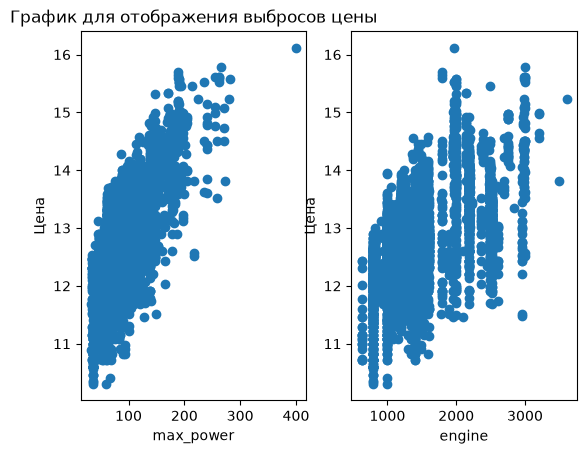

max_power    0.652186
engine       0.470115
dtype: float64


In [15]:
fig, ax = plt.subplots(1,2)

ax[0].scatter(dataset['max_power'], np.log1p(dataset['selling_price']),label = 'selling price')

ax[0].set_title('График для отображения выбросов цены')
ax[0].set_ylabel('Цена')
ax[0].set_xlabel('max_power')
ax[1].set_ylabel('Цена')
ax[1].set_xlabel('engine')
ax[1].scatter(dataset['engine'], np.log1p(dataset['selling_price']),label = 'selling price')
plt.show()

print(X_train[['max_power', 'engine']].corrwith(np.log1p(y_train)))

In [16]:


pred = cross_val_predict(model_rf, X_train, y_train, cv=5)
err = np.abs(pred - y_train)
rel = err / y_train
cheap = y_train < 1_500_000

print(err[cheap].mean(), err[~cheap].mean())
print(rel[cheap].median(), rel[~cheap].median())
print(cheap.sum(), (~cheap).sum())

66148.58304153128 472619.7728842309
0.11908195125329898 0.12942080130882502
5166 191


## Вывод

1. В качестве baseline выбираем медиану: MAE ≈ 281 ± 6 тыс. ₽ (CV на train), это ≈ 66% от медианной цены (425 тыс. ₽). Медиана показала лучший результат, чем среднее (≈ 295 ± 6 тыс. ₽), и выигрывает в каждом из пяти фолдов.

2. Полученная модель (RandomForest с обучением на log1p цены) показала хороший результат, лучше, чем я мог предположить: MAE ≈ 81 ± 5 тыс. ₽, это на ≈ 71% лучше baseline и ≈ 19% от медианной цены. Разница с baseline намного больше std, значит, это не шум.

3. Оценка кросс-валидацией на тренировочных данных показала, что цель выполнена (≤ 127 тыс. ₽ и ≤ 106 тыс. ₽), но это ещё не значит, что модель очень хороша, так как её ещё не проверяли на тестовых данных.

4. Корреляции с log1p(цена): max_power 0.65, engine 0.47. Связь с ценой заметная, у max_power сильнее. Корреляция измеряет линейную связь и не доказывает влияние, к тому же признаки связаны между собой. Разброс медиан по маркам большой (от ≈ 265 тыс. ₽ у Tata до ≈ 2,5 млн ₽ у BMW), значит, марка тоже несёт информацию.

5. Сегменты цены (CV-предсказания на train):

   | Сегмент | Машин | MAE, ₽ | Медиана относительной ошибки |
   |---|---|---|---|
   | дешевле 1,5 млн | 5182 | ≈ 65 тыс. | ≈ 11,8% |
   | от 1,5 млн | 190 | ≈ 504 тыс. | ≈ 15,1% |

   Точно утверждать, что дорогим машинам модель подходит хуже, нельзя: их всего 190 (3,5%), а разница в относительной ошибке мала (≈ 3 п.п.). В такой маленькой группе одна машина (например, Volvo за 10 млн) может заметно менять результат. При этом эти 190 машин дают ≈ 22% суммарной ошибки, поэтому MAE в рупиях «раздут» дорогими машинами.

6. Ограничения: удалены 1202 дубликата и 209 строк без характеристик (для таких машин модель не работает); были смешаны единицы kmpl и km/kg; torque не использовали (разные единицы, грязный формат); нет данных о состоянии, торге и регионе; одна из двух записей с нереальным пробегом находится в test и не удалялась; модель одна, с гиперпараметрами по умолчанию.

7. Дальше (неделя 14): подбор гиперпараметров по CV, сравнение с LightGBM, новые признаки (возраст машины, модель авто), оценка на test один раз в конце.

In [17]:
dataset[features+['selling_price']].duplicated().sum()

np.int64(0)